# Análisis del comportamiento meteorológico y variables climáticas (ENE -JUN 2012)

## 2da Pre-Entrega

## GRUPO 9


*   Oscar Luis Gallardo
*   Gabriel Ollier
*   Augusto Rosso




## Objetivos
Explorar y comprender la distribución de las variables meteorológicas (temperatura, humedad, presión, radiación), identificar patrones estacionales a lo largo del año, detectar y limpiar anomalías en las mediciones, y encontrar correlaciones clave entre los distintos fenómenos climáticos.

- reconocer la estructura y el significado de un dataset;
- diferenciar variables numéricas, categóricas, temporales e identificadores;
- detectar faltantes, duplicados, formatos inconsistentes y valores atípicos;
- justificar decisiones de limpieza según el contexto;
- transformar variables y crear nuevas características interpretables.


## Variable objetivo

> **La variable objetivo es la temperatura ambiental (`temp_c`), y el objetivo del proyecto es pronosticarla y estimarla con precisión analizando su comportamiento en función de factores meteorológicos clave, como la presión atmosférica, la radiación solar y la humedad.**

# Parte 1 — Carga y exploración inicial

## Conociendo nuestro dataset



## Preparación: cargar el dataset

In [1]:
# impotamos la libreria y le asignamos el alias correspondiente.
import os
import pandas as pd

# Ruta de Colab; si no existe (ejecución local), se usa la copia subida
ruta = '/content/informacion-meteorologica-2012.csv'
if not os.path.exists(ruta):
    ruta = '/mnt/user-data/uploads/informacion-meteorologica-2012.csv'
df = pd.read_csv(ruta)

In [2]:
display(df.shape)#dimensiones del dataset

(29559, 11)

In [3]:
df.head(10)#vista inicial

,fecha,hora,estacion,vv_m_s,dv,temp_c,hr_porc,press_mbar,pluv_mm,rad_sol_w_m2,uv_uvindex
0,2012-01-01,00:00:00,1283,0.4,67.5,24.6,65,1010.8,0,0,0.0
1,2012-01-01,00:00:00,1284,2.7,135.0,24.8,60,1011.6,0,0,0.0
2,2012-01-01,00:00:00,1286,0.0,112.5,24.8,60,1012.6,0,0,0.0
3,2012-01-01,00:00:00,1291,0.0,180.0,24.6,59,1011.5,0,0,0.0
4,2012-01-01,00:00:00,1296,0.4,45.0,24.9,57,1010.4,0,0,0.0
5,2012-01-01,00:00:00,1305,0.4,90.0,25.1,61,1010.5,0,0,0.0
6,2012-01-01,00:00:00,1309,3.6,90.0,24.1,71,1011.7,0,0,0.0
7,2012-01-01,00:00:00,1310,2.7,90.0,24.7,60,1012.0,0,0,0.0
8,2012-01-01,00:00:00,1314,1.8,90.0,25.1,58,1010.7,0,0,0.0
9,2012-01-01,00:00:00,1318,0.4,67.5,1802.6,60,1011.9,0,0,0.0


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 29559 entries, 0 to 29558
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   fecha         29559 non-null  str    
 1   hora          29559 non-null  str    
 2   estacion      29559 non-null  int64  
 3   vv_m_s        29559 non-null  float64
 4   dv            29559 non-null  float64
 5   temp_c        29559 non-null  float64
 6   hr_porc       29559 non-null  int64  
 7   press_mbar    29559 non-null  float64
 8   pluv_mm       29559 non-null  int64  
 9   rad_sol_w_m2  29559 non-null  int64  
 10  uv_uvindex    29559 non-null  float64
dtypes: float64(5), int64(4), str(2)
memory usage: 2.5 MB


In [5]:
display(df.dtypes)

fecha               str
hora                str
estacion          int64
vv_m_s          float64
dv              float64
temp_c          float64
hr_porc           int64
press_mbar      float64
pluv_mm           int64
rad_sol_w_m2      int64
uv_uvindex      float64
dtype: object

In [6]:
df.isnull().sum()

fecha           0
hora            0
estacion        0
vv_m_s          0
dv              0
temp_c          0
hr_porc         0
press_mbar      0
pluv_mm         0
rad_sol_w_m2    0
uv_uvindex      0
dtype: int64

In [7]:
df.duplicated().sum()

np.int64(0)

In [8]:
df[df.duplicated()]

,fecha,hora,estacion,vv_m_s,dv,temp_c,hr_porc,press_mbar,pluv_mm,rad_sol_w_m2,uv_uvindex


##  Identificación de variables


In [9]:
df.columns

Index(['fecha', 'hora', 'estacion', 'vv_m_s', 'dv', 'temp_c', 'hr_porc',
       'press_mbar', 'pluv_mm', 'rad_sol_w_m2', 'uv_uvindex'],
      dtype='str')

## Diccionario de variables

| Variable | Significado esperado | Tipo conceptual |
|---|---|---|
| `fecha` |Fecha en la que se realizó la medición | Temporal |
| `hora` |	Hora exacta de la medición |	Temporal
| `estación` |	Identificador de la estación meteorológica |	Identificador
| `vv_m_s` |	Velocidad del viento en metros por segundo |	Numérica continua
| `dv` |	Dirección del viento (en grados) |	Numérica continua
| `temp_c` |	Temperatura en grados Celsius |	Numérica continua
| `hr_proc` |	Humedad relativa en porcentaje |	Numérica discreta
| `press_mbar` |	Presión atmosférica en milibares |	Numérica continua
| `pluv_mm` |	Precipitación pluvial (lluvia) en milímetros |	Numérica discreta
| `rad_sol_w_m2` |	Radiación solar en vatios por metro cuadrado |	Numérica discreta
| `uv_uvindex` |	Índice ultravioleta (UV) |	Numérica continua


## Conclusiones de la Exploración Inicial

- El dataset cuenta con 29,559 registros y 11 variables.
- No se detectaron valores nulos ni filas duplicadas, lo que permite avanzar sin necesidad de aplicar técnicas de imputación.
- Las variables numéricas están correctamente en formatos float64 e int64. Las columnas temporales (fecha y hora) están separadas y en formato de texto (object), lo que requiere una transformación a datetime para poder realizar análisis estacionales.
- Sin entrar mucho en detalle, simplemente imprimiendo unas filas se detectó un error físico en las mediciones. La fila de índice 9 registra un valor en temp_c de 1802.6 °C. Esto es algo que vamos a tener en cuenta en el analisís futuro.

In [10]:
df["estacion"].unique()

array([1283, 1284, 1286, 1291, 1296, 1305, 1309, 1310, 1314, 1318, 1316,
       1295, 1289, 1304, 1315])

In [11]:
df["estacion"].value_counts()

estacion
1286    3385
1289    2713
1310    2571
1284    2548
1291    2313
1318    2115
1296    2030
1305    1984
1309    1847
1283    1834
1316    1712
1315    1372
1304    1272
1314    1013
1295     850
Name: count, dtype: int64

Existe un desbalance en la cantidad de mediciones por estación. Las tres estaciones que más datos aportaron al dataset son la 1286 (3.385 registros), la 1289 (2.713 registros) y la 1310 (2.571 registros). Por el contrario, la estación 1295 es la que menos actividad registró, con apenas 850 mediciones.

## Deteccion de outliers

Defino cuartiles y rango intercuartilico para ver en el dataframe los valores atipicos.

In [12]:
Q1 = df['temp_c'].quantile(0.25)
Q3 = df['temp_c'].quantile(0.75)
IQR = Q3 - Q1
limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR
print(f"Q1: {Q1}\nQ3: {Q3}\nIQR: {IQR}\nLimite inferior: {limite_inferior}\nLimite superior: {limite_superior}")

Q1: 16.1
Q3: 25.6
IQR: 9.5
Limite inferior: 1.8500000000000014
Limite superior: 39.85


In [13]:
outliers_temp = df[(df['temp_c'] < limite_inferior) | (df['temp_c'] > limite_superior)]
display(outliers_temp)
outliers_temp.count()
outliers_temp.groupby('temp_c').count()

,fecha,hora,estacion,vv_m_s,dv,temp_c,hr_porc,press_mbar,pluv_mm,rad_sol_w_m2,uv_uvindex
9,2012-01-01,00:00:00,1318,0.4,67.5,1802.6,60,1011.9,0,0,0.0
59,2012-01-01,05:00:00,1318,0.4,90.0,1802.6,255,1012.8,0,0,0.0
99,2012-01-01,09:00:00,1318,0.9,67.5,1802.6,68,1015.1,0,459,10.3
129,2012-01-01,12:00:00,1318,1.3,90.0,1802.6,62,1014.2,0,933,15.8
139,2012-01-01,13:00:00,1318,1.3,90.0,1802.6,62,1013.4,0,997,16.0
183,2012-01-01,17:00:00,1318,0.9,67.5,1802.6,60,1011.1,0,571,9.6
326,2012-01-02,06:00:00,1318,0.0,67.5,1802.6,68,1011.1,0,0,0.0
478,2012-01-02,20:00:00,1318,0.0,270.0,1802.6,51,1006.4,0,11,0.0
827,2012-01-04,04:00:00,1318,0.0,67.5,1802.6,75,1012.2,0,0,0.0
1179,2012-01-05,12:00:00,1318,0.4,270.0,1802.6,51,1011.6,0,949,13.9


,fecha,hora,estacion,vv_m_s,dv,hr_porc,press_mbar,pluv_mm,rad_sol_w_m2,uv_uvindex
temp_c,,,,,,,,,,
1.1,2,2,2,2,2,2,2,2,2,2
1.3,4,4,4,4,4,4,4,4,4,4
1.4,2,2,2,2,2,2,2,2,2,2
1.5,1,1,1,1,1,1,1,1,1,1
1.6,1,1,1,1,1,1,1,1,1,1
1.7,4,4,4,4,4,4,4,4,4,4
1802.6,600,600,600,600,600,600,600,600,600,600


El valor maximo de 1802.6 en temp_c se repite en 600 filas, lo cual es raro que se replique en un volumen así. Estos valores de primera son fisicamente imposibles en un contexto normal, por lo que podria ser un error de lectura, de decimales, o escala.

Este valor atipíco afecta la media y la desviacion estandar. La desviacion estandar tiene un valor de 251.39, a pesar de que el 75% de los valores estan por debajo de 25.6, esto arrastra la media al valor de 56.72, frente a una mediana de 21.3..

# Parte 2 — Analisis avanzado, transformación y limpieza de datos

## Conversión de fechas

`fecha` y `hora` representan fechas, aunque inicialmente estén almacenadas como texto.



In [14]:
df_copia = df.copy()

fecha_nueva = pd.to_datetime(df["fecha"], format="mixed")
hora_nueva = pd.to_datetime(df["hora"], format="mixed")
df_copia["fecha"] = fecha_nueva
df_copia["hora"] = hora_nueva

## Tratamiento de outliers.

Con la deteccion de los outliers, se procede a visualizar y analizar como se los va a tratar.

In [15]:
porcentaje_outliers = outliers_temp['temp_c'].count() / df['temp_c'].count() * 100
outliers_temp['temp_c'].count()
df['temp_c'].count()

print(f"El numero de outliers es de {outliers_temp['temp_c'].count()}")
print(f"El numero de valores totales es de {df['temp_c'].count()}")
print(f"El porcentaje de outliers es de {porcentaje_outliers:.2f}%")

El numero de outliers es de 614
El numero de valores totales es de 29559
El porcentaje de outliers es de 2.08%


In [16]:
outliers_temp['temp_c'].groupby(outliers_temp['temp_c']).count()

temp_c
1.1         2
1.3         4
1.4         2
1.5         1
1.6         1
1.7         4
1802.6    600
Name: temp_c, dtype: int64

Al analizar en detalle los 614 outliers detectados por el método IQR, se identificó que 600 de ellos corresponden a un único valor anómalo sistemático (1802.6 °C), el cual representa un error de lectura del sensor. El resto de los registros atípicos detectados por el límite inferior (valores entre 1.1°C y 1.7°C) corresponden a mediciones de temperaturas bajas reales y válidas para el contexto climático, por lo que se decidió aislar y eliminar únicamente el error de hardware sin descartar la variabilidad climática genuina.

In [17]:
df_limpio = df_copia[df_copia['temp_c'] != 1802.6].copy()

In [18]:
df_limpio.describe()

,fecha,hora,estacion,vv_m_s,dv,temp_c,hr_porc,press_mbar,pluv_mm,rad_sol_w_m2,uv_uvindex
count,28959,28959,28959.000000,28959.000000,28959.000000,28959.000000,28959.000000,28959.000000,28959.000000,28959.000000,28959.000000
mean,2012-03-23 23:44:50.023826,2026-11-20 11:29:42.285300,1298.819814,0.652471,154.866104,20.544511,67.769605,1011.554663,0.402638,140.416106,1.737940
min,2012-01-01 00:00:00,2026-11-20 00:00:00,1283.000000,0.000000,0.000000,1.100000,20.000000,994.400000,0.000000,0.000000,0.000000
25%,2012-01-27 00:00:00,2026-11-20 05:00:00,1286.000000,0.000000,67.500000,15.900000,56.000000,1007.800000,0.000000,0.000000,0.000000
50%,2012-03-28 00:00:00,2026-11-20 11:00:00,1296.000000,0.400000,135.000000,21.200000,67.000000,1011.400000,0.000000,3.000000,0.000000
75%,2012-05-04 00:00:00,2026-11-20 17:00:00,1310.000000,0.900000,247.500000,25.300000,77.000000,1014.800000,0.000000,152.000000,2.200000
max,2012-07-17 00:00:00,2026-11-20 23:00:00,1318.000000,9.800000,337.500000,39.600000,255.000000,1033.700000,237.000000,1145.000000,16.000000
std,NaN,NaN,12.181209,0.891724,102.623178,6.558238,22.347128,5.052816,4.926945,244.734667,3.301751


## Feature Engineering

Se extraen datos especificos como el mes y la hora del dia.

In [19]:
df_limpio['mes'] = df_limpio['fecha'].dt.month
df_limpio['hora_del_dia'] = pd.to_datetime(df_limpio['hora'], format='mixed').dt.hour

## Visualizacion de correlaciones

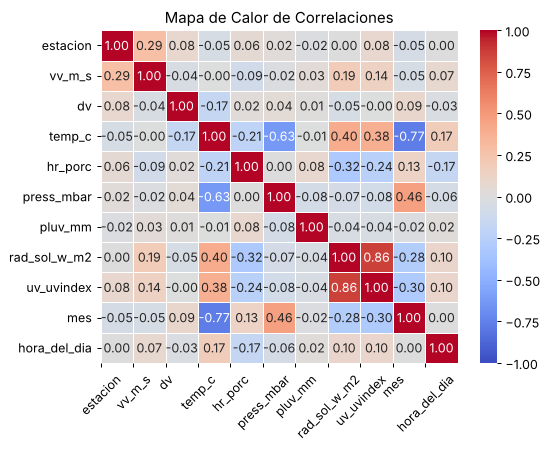

In [20]:
import seaborn as sns
import matplotlib.pyplot as plt

df_num = df_limpio.select_dtypes(include=['number'])

sns.heatmap(df_num.corr(), annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5, vmin=-1, vmax=1)
plt.title('Mapa de Calor de Correlaciones')
x_labels = df_num.columns
plt.xticks(range(len(x_labels)), x_labels, rotation=45)
plt.show()

Del análisis de la matriz de correlación se desprende que la temperatura ambiental (temp_c) está fuertemente condicionada por factores estacionales y energéticos. La radiación solar ($0.40$) y el índice UV ($0.38$) operan como los principales inductores positivos del aumento térmico. Por otro lado, se destaca una marcada relación inversa con la presión atmosférica ($-0.63$) y el avance de los meses del año ($-0.77$), evidenciando los cambios estacionales del período 2012. Variables como la humedad relativa muestran un peso moderado ($-0.21$), mientras que el viento y las precipitaciones presentan una incidencia lineal directa menor sobre la temperatura general.

Tomando la fuerte relacion inversa de la temperatura con el avance de los meses del año, se visualiza un grafico de lineas.

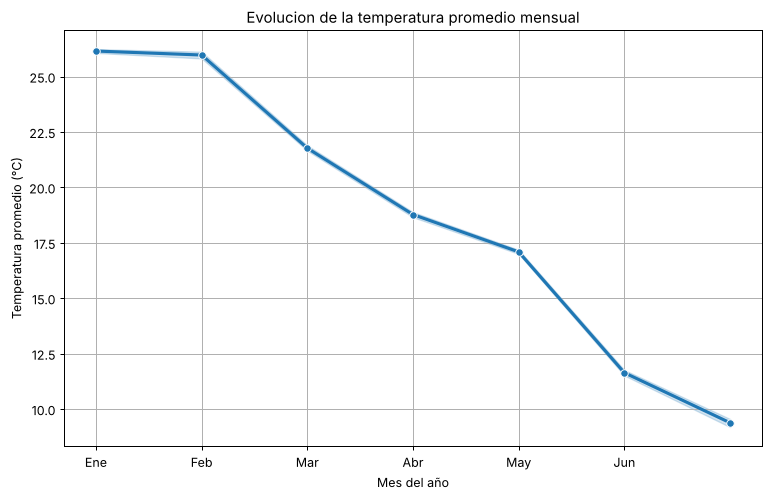

In [21]:
plt.figure(figsize=(10,6))

sns.lineplot(data=df_limpio, x='mes', y='temp_c', estimator='mean', marker='o', linewidth=2.5)

plt.title("Evolucion de la temperatura promedio mensual")
plt.xlabel("Mes del año")
plt.ylabel("Temperatura promedio (°C)")
plt.xticks(range(1, 7), labels=['Ene', 'Feb', 'Mar', 'Abr', 'May', 'Jun'])
plt.grid(True)
plt.show()

Se puede ver de manera mas clara esta correlacion, a medida que avanzan los meses, disminuye la temperatura promedio.

Tomando el analisis anterior de los registros por estacion, se visualiza como se comportan las temperaturas en cada una.

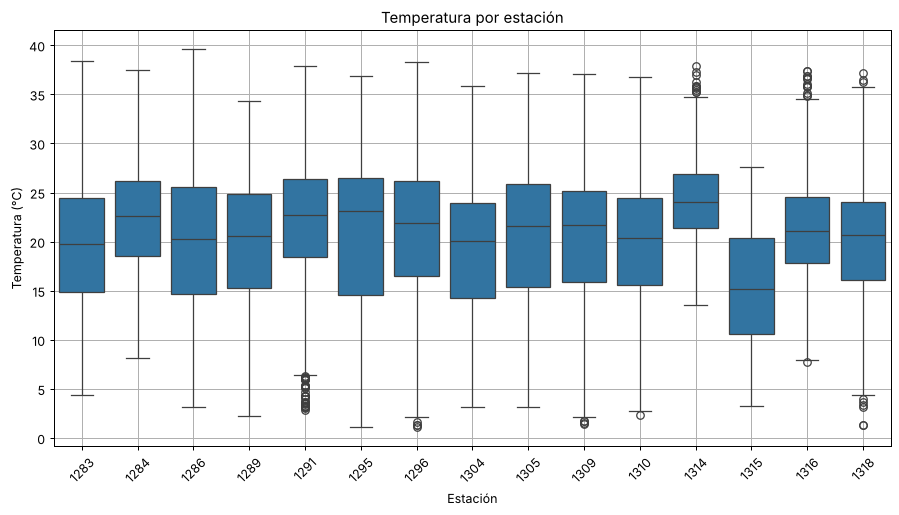

In [22]:
plt.figure(figsize=(12,6))

sns.boxplot(data=df_limpio, x='estacion', y='temp_c')

plt.title("Temperatura por estación")
plt.xlabel("Estación")
plt.ylabel("Temperatura (°C)")
plt.xticks(rotation=45)
plt.grid(True)

# Parte 3 - Preparacion de datos para modelo de Machine Learning.

In [23]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

Como las estaciones son códigos numéricos discretos que representan categorías ( IDs de dispositivos meteorológicos como 1283, 1284), el modelo de Random Forest podría interpretarlas como valores ordinales (es decir, asume que la estación 1318 es "mayor" que la 1283). Para que el modelo aprenda correctamente sin sesgos de orden numérico aplicamos One-Hot Encoding

In [24]:
df_limpio['estacion'] = df_limpio['estacion'].astype(str)

df_model = pd.get_dummies(df_limpio, columns=['estacion'], drop_first=True)

# Actualizamos las variables predictoras (X) incorporando las nuevas columnas de estaciones
variables_predictoras = [col for col in df_model.columns if col not in ['fecha', 'hora', 'temp_c']]
X = df_model[variables_predictoras]
y = df_model['temp_c']
y_clasificacion = df_model['temp_c']

In [25]:
# Ordenar el dataset cronológicamente por seguridad
df_limpio = df_limpio.sort_values(['fecha', 'hora']).reset_index(drop=True)

# One-Hot Encoding de la estación (el Random Forest no acepta strings)
df_model = pd.get_dummies(df_limpio, columns=['estacion'], drop_first=True)

# Definir variables predictoras (X) y objetivo (y)
features = ['vv_m_s', 'dv', 'hr_porc', 'press_mbar', 'pluv_mm', 'rad_sol_w_m2', 'uv_uvindex', 'mes', 'hora_del_dia'] \
           + [c for c in df_model.columns if c.startswith('estacion_')]
X = df_model[features]
y = df_model['temp_c']

# División cronológica: Entrenamiento (Ene - Abr) y Evaluación (May - Jul)
mask_train = df_limpio['fecha'] < '2012-05-01'

X_train = X[mask_train]
y_train = y[mask_train]
X_test = X[~mask_train]
y_test = y[~mask_train]

print(f"Dimensiones de entrenamiento: {X_train.shape}")
print(f"Dimensiones de prueba (evaluación a ciegas): {X_test.shape}")

Dimensiones de entrenamiento: (21118, 23)
Dimensiones de prueba (evaluación a ciegas): (7841, 23)


## Modelo de regresion.

El objetivo principal del proyecto es estimar la temperatura ambiental temp_c. Por eso, el modelo de regresión es el más alineado con el problema planteado.

Se importa modelo y metricas

In [26]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

Se llama a modelo y se entrena.

In [27]:
rf_reg = RandomForestRegressor(random_state=42)
rf_reg.fit(X_train, y_train)

RandomForestRegressor(random_state=42)

In [28]:
y_pred_rf = rf_reg.predict(X_test)

Metricas de prediccion realizada.

In [29]:
print(f"MSE: {mean_squared_error(y_test, y_pred_rf)}")
print(f"RMSE: {np.sqrt(mean_squared_error(y_test, y_pred_rf))}")
print(f"R2: {r2_score(y_test, y_pred_rf)}")

MSE: 44.09064372477999
RMSE: 6.640078593268305
R2: -1.1963863622145485


En el corte cronológico (entrenamiento ene-abr, prueba may-jul), las predicciones del modelo base se desvían en promedio unos 6,64 °C (RMSE) y el R² es de −1,20: peor que predecir siempre la media del test. La causa se analiza en la sección «Corrección de la evaluación cronológica».

## Modelo de clasificacion.

Si se quiere hacer un modelo de clasifiacion basado en la temperatura, se puede clasificar en temperatura baja o alta, basado en un umbral parametrizado. Se trata de una clasificación binaria construida a partir de la mediana, no de categorías meteorológicas oficiales de frío y calor.

In [30]:
mediana_temp = df_limpio['temp_c'].median()
print("Umbral (mediana de la temperatura) : "+str(mediana_temp))

Umbral (mediana de la temperatura) : 21.2


Se crea columna binaria para clasificar.

In [31]:
df_limpio['temp_clase'] = (df_limpio['temp_c'] > mediana_temp).astype(int)

Definicion de variable objetivo.

In [32]:
y_clasificacion = df_limpio['temp_clase']

Diviendo en train y test.

In [33]:
X_train_clasificacion, X_test_clasificacion, y_train_clasificacion, y_test_clasificacion = train_test_split(X, y_clasificacion, test_size=0.2, random_state=42)

Importacion de modelo de clasificacion.

In [34]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

Llamado a modelo y entrenamiento

In [35]:
rf_clf = RandomForestClassifier(random_state=42)
rf_clf.fit(X_train_clasificacion, y_train_clasificacion)

RandomForestClassifier(random_state=42)

Prediccion.

In [36]:
y_pred_clf = rf_clf.predict(X_test_clasificacion)

Metricas de prediccion.

In [37]:
print(f"Accuracy: {accuracy_score(y_test_clasificacion, y_pred_clf)}")
print(f"Classification Report:\n{classification_report(y_test_clasificacion, y_pred_clf)}")


Accuracy: 0.9307665745856354
Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.92      0.93      2949
           1       0.92      0.94      0.93      2843

    accuracy                           0.93      5792
   macro avg       0.93      0.93      0.93      5792
weighted avg       0.93      0.93      0.93      5792



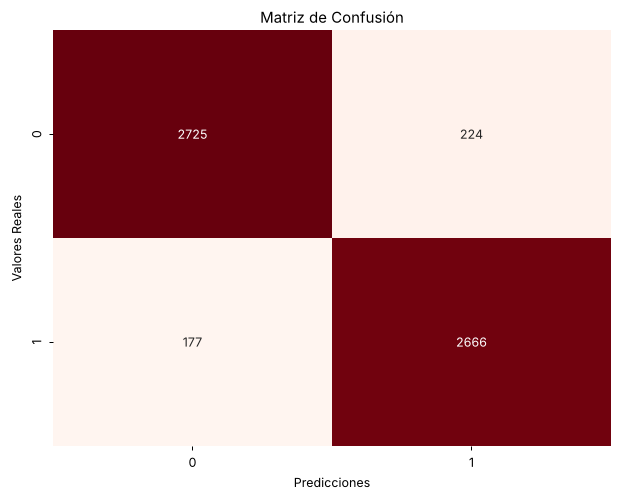

In [38]:
confusion_matrix(y_test_clasificacion, y_pred_clf)
plt.figure(figsize=(8, 6))
sns.heatmap(confusion_matrix(y_test_clasificacion, y_pred_clf), annot=True, fmt='d', cmap='Reds', cbar=False)
plt.title('Matriz de Confusión')
plt.xlabel('Predicciones')
plt.ylabel('Valores Reales')
plt.show()

En el corte cronológico (entrenamiento ene-abr, prueba may-jul), el modelo de regresión (`RandomForestRegressor`) obtuvo $R^2 = -1,20$ y un RMSE de $6,64$ °C, es decir, peor que predecir siempre la media del conjunto de prueba. La causa es un cambio de distribución entre train y test y se analiza más abajo.

El modelo de clasificación (`RandomForestClassifier`), evaluado con un split aleatorio 80/20 y la mediana de $21,2$ °C como umbral binario, logró un *Accuracy* del $93,08\%$ con precisión y *recall* entre $0,92$ y $0,94$ en ambas clases. Ese valor es optimista: en un split aleatorio, registros contiguos de una misma estación quedan repartidos entre train y test, por lo que no equivale a pronosticar el futuro. La evaluación cronológica de la clasificación se presenta en la sección de corrección.

###  Overfitting

Restricción de la complejidad del modelo: optimizamos los hiperparámetros limitando la complejidad de los árboles (max_depth=20 y min_samples_split=5), lo que frena la memorización excesiva del ruido.

In [39]:
# Instanciamos los modelos limitando la complejidad para evitar overfitting
rf_reg_opt = RandomForestRegressor(max_depth=20, min_samples_split=5, random_state=42)
rf_clf_opt = RandomForestClassifier(max_depth=20, min_samples_split=5, random_state=42)

# Entrenamos de nuevo
rf_reg_opt.fit(X_train, y_train)
rf_clf_opt.fit(X_train_clasificacion, y_train_clasificacion)

# Verificamos nuevas métricas en Test
print("Regresión Optimizada R2 Test:", r2_score(y_test, rf_reg_opt.predict(X_test)))
print("Clasificación Optimizada Accuracy Test:", accuracy_score(y_test_clasificacion, rf_clf_opt.predict(X_test_clasificacion)))

Regresión Optimizada R2 Test: -1.1953251360805788
Clasificación Optimizada Accuracy Test: 0.9262776243093923


In [40]:
from sklearn.metrics import confusion_matrix, classification_report

# Generamos las predicciones con el modelo optimizado
y_pred_opt_clf = rf_clf_opt.predict(X_test_clasificacion)

# Mostramos el reporte y la matriz de confusión
print(f"Accuracy Optimizado: {accuracy_score(y_test_clasificacion, y_pred_opt_clf):.4f}")
print(f"Classification Report:\n{classification_report(y_test_clasificacion, y_pred_opt_clf)}")

Accuracy Optimizado: 0.9263
Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.92      0.93      2949
           1       0.91      0.94      0.93      2843

    accuracy                           0.93      5792
   macro avg       0.93      0.93      0.93      5792
weighted avg       0.93      0.93      0.93      5792



Text(0.5, 1.0, 'Matriz de Confusión')

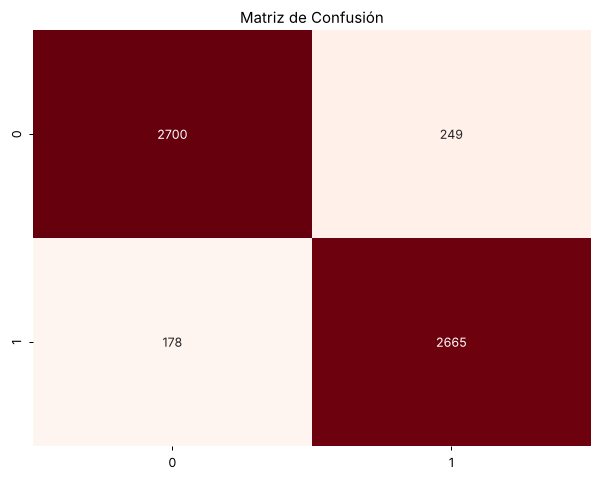

In [41]:
plt.figure(figsize=(8, 6))
sns.heatmap(confusion_matrix(y_test_clasificacion, y_pred_opt_clf), annot=True, fmt='d', cmap='Reds', cbar=False)
plt.title('Matriz de Confusión')

Con el modelo optimizado (split aleatorio 80/20) la clase 0 (temperatura baja, $\le 21,2$ °C) tiene precisión $0,94$ y *recall* $0,92$, y la clase 1 (temperatura alta, $> 21,2$ °C) precisión $0,91$ y *recall* $0,94$; el *Accuracy* es $92,63\%$. La matriz de confusión se muestra en la figura anterior.

Control de overfitting: al restringir la complejidad, el *Accuracy* en entrenamiento baja de 99,99 % a 98,66 % y el de prueba pasa de 93,08 % a 92,63 %.

La brecha entre entrenamiento y prueba se reduce, pero el desempeño en prueba no mejora (queda 0,45 puntos por debajo del modelo sin restringir). Además, al tratarse de un split aleatorio, estas cifras no miden la capacidad de pronosticar el futuro.

## Comparacion desempeño sobre datos de entrenamiento y prueba.

### Regresion

In [42]:
print("Regresión R2 Train:", rf_reg.score(X_train, y_train))
print("Regresión R2 Test:", rf_reg.score(X_test, y_test))

print("Regresión optimizada R2 Train:",
      rf_reg_opt.score(X_train, y_train))

print("Regresión optimizada R2 Test:",
      rf_reg_opt.score(X_test, y_test))

Regresión R2 Train: 0.987753425351867
Regresión R2 Test: -1.1963863622145485
Regresión optimizada R2 Train: 0.9796501056107485
Regresión optimizada R2 Test: -1.1953251360805788


En entrenamiento el modelo base explica el 98,78 % de la variabilidad ($R^2 = 0,988$) y el optimizado el 97,97 %. En prueba cronológica ambos tienen $R^2 \approx -1,20$.

La brecha es enorme, pero no se debe solo a sobreajuste: el conjunto de prueba (may-jul) tiene una distribución de temperaturas distinta a la del entrenamiento (ver diagnóstico más abajo). Los hiperparámetros elegidos manualmente no mejoran el $R^2$ de prueba.

### Clasificacion

In [43]:
print("Clasificación Accuracy Train:", rf_clf.score(X_train_clasificacion, y_train_clasificacion))
print("Clasificación Accuracy Test:", rf_clf.score(X_test_clasificacion, y_test_clasificacion))

print("Clasificación optimizada Accuracy Train:", rf_clf_opt.score(X_train_clasificacion, y_train_clasificacion))
print("Clasificación optimizada Accuracy Test:", rf_clf_opt.score(X_test_clasificacion, y_test_clasificacion))

Clasificación Accuracy Train: 0.999913670306902
Clasificación Accuracy Test: 0.9307665745856354
Clasificación optimizada Accuracy Train: 0.9866188975698191
Clasificación optimizada Accuracy Test: 0.9262776243093923


En el modelo de clasificación (split aleatorio), el modelo base clasifica correctamente el 93,08 % de los registros de prueba y el 99,99 % de los de entrenamiento, lo que indica sobreajuste. La versión optimizada reduce el *Accuracy* de entrenamiento a 98,66 % y obtiene 92,63 % en prueba: reduce el sobreajuste sin mejorar la prueba.

## Optimizacion hiperparametros con GridSearchCV

In [44]:
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score

# 1. Asegurar el orden cronológico del DataFrame
# (df_limpio ya está ordenado cronológicamente desde la Parte 3)

# 2. Definir features y variable objetivo
X = df_model[features]

y_clf = df_limpio['temp_clase']

# 3. División cronológica: Entrenamiento (Ene - Abr) y Evaluación (May - Jul)
mask_train = df_limpio['fecha'] < '2012-05-01'

X_train_c = X[mask_train]
y_train_c = y_clf[mask_train]
X_test_c = X[~mask_train]
y_test_c = y_clf[~mask_train]

# 4. Configurar validación cruzada para series temporales
tscv = TimeSeriesSplit(n_splits=5)

# 5. Definir y entrenar el clasificador con GridSearchCV
rf_classifier = RandomForestClassifier(random_state=42)

param_grid_clf = {
    'n_estimators': [50, 100],
    'max_depth': [10, 15],
    'min_samples_split': [5, 10],
    'min_samples_leaf': [4, 8]
}

grid_search_clf = GridSearchCV(
    estimator=rf_classifier,
    param_grid=param_grid_clf,
    cv=tscv,
    scoring='f1_macro',  # f1_macro: la clase 'alta' es minoritaria en el test cronológico
    n_jobs=-1
)

grid_search_clf.fit(X_train_c, y_train_c)

print("Mejores hiperparámetros (Clasificación):", grid_search_clf.best_params_)

# 6. Evaluar en el conjunto de prueba cronológico (May-Jun)
best_clf_model = grid_search_clf.best_estimator_
y_pred_c = best_clf_model.predict(X_test_c)

print("\n--- Resultados en Test (Evaluación a ciegas) ---")
print(f"Accuracy: {accuracy_score(y_test_c, y_pred_c):.4f}")
print("\nReporte de Clasificación:")
print(classification_report(y_test_c, y_pred_c))

Mejores hiperparámetros (Clasificación): {'max_depth': 15, 'min_samples_leaf': 4, 'min_samples_split': 10, 'n_estimators': 50}

--- Resultados en Test (Evaluación a ciegas) ---
Accuracy: 0.7797

Reporte de Clasificación:
              precision    recall  f1-score   support

           0       0.98      0.79      0.87      7594
           1       0.06      0.41      0.11       247

    accuracy                           0.78      7841
   macro avg       0.52      0.60      0.49      7841
weighted avg       0.95      0.78      0.85      7841



Validacion cruzada para modelo de regresion.

In [45]:
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score

# Configurar el esquema de validación cruzada para series temporales
tscv = TimeSeriesSplit(n_splits=5)

# Definir el modelo
rf_regressor = RandomForestRegressor(random_state=42)

# Espacio de hiperparámetros (respetando la limitación de profundidad y nodos para evitar overfitting)
param_grid = {
    'n_estimators': [50, 100],
    'max_depth': [10, 15],
    'min_samples_split': [5, 10],
    'min_samples_leaf': [4, 8]
}

# GridSearchCV utilizando TimeSeriesSplit
grid_search = GridSearchCV(
    estimator=rf_regressor,
    param_grid=param_grid,
    cv=tscv,
    scoring='neg_mean_squared_error',
    n_jobs=-1
)

# Entrenar el modelo
grid_search.fit(X_train, y_train)

print("Mejores hiperparámetros encontrados:", grid_search.best_params_)

# Evaluar en el conjunto de prueba cronológico (May-Jun)
best_model = grid_search.best_estimator_
y_pred = best_model.predict(X_test)

print(f"MSE en test: {mean_squared_error(y_test, y_pred):.4f}")
print(f"R2 Score en test: {r2_score(y_test, y_pred):.4f}")

Mejores hiperparámetros encontrados: {'max_depth': 10, 'min_samples_leaf': 4, 'min_samples_split': 5, 'n_estimators': 50}
MSE en test: 43.1979
R2 Score en test: -1.1519


##Evaluacion modelos con GridSearch

In [46]:
# ==========================================
# 1. EVALUACIÓN DE CLASIFICACIÓN (Con GridSearch)
# ==========================================
print("--- MODELO DE CLASIFICACIÓN ---")
# Usamos el grid_search específico de clasificación
mejor_clf = grid_search_clf.best_estimator_
y_pred_mejor_clf = mejor_clf.predict(X_test_c)

print("Accuracy en train:", mejor_clf.score(X_train_c, y_train_c))
print("Accuracy en test:", mejor_clf.score(X_test_c, y_test_c))
print("Classification Report:\n", classification_report(y_test_c, y_pred_mejor_clf))
print("Matriz de confusion:\n", confusion_matrix(y_test_c, y_pred_mejor_clf))


# ==========================================
# 2. EVALUACIÓN DE REGRESIÓN (Con GridSearch)
# ==========================================
print("\n--- MODELO DE REGRESIÓN ---")
# Usamos el grid_search específico de regresión
mejor_reg = grid_search.best_estimator_ # O grid_search_reg si lo renombraste así
y_pred_mejor_reg = mejor_reg.predict(X_test)

print("R2 en train:", mejor_reg.score(X_train, y_train))
print("R2 en test:", r2_score(y_test, y_pred_mejor_reg))
print("RMSE en test:", np.sqrt(mean_squared_error(y_test, y_pred_mejor_reg)))
print("MSE en test:", mean_squared_error(y_test, y_pred_mejor_reg))

--- MODELO DE CLASIFICACIÓN ---
Accuracy en train: 0.9368311393124349
Accuracy en test: 0.7797474811886239
Classification Report:
               precision    recall  f1-score   support

           0       0.98      0.79      0.87      7594
           1       0.06      0.41      0.11       247

    accuracy                           0.78      7841
   macro avg       0.52      0.60      0.49      7841
weighted avg       0.95      0.78      0.85      7841

Matriz de confusion:
 [[6012 1582]
 [ 145  102]]

--- MODELO DE REGRESIÓN ---
R2 en train: 0.8997380462838622
R2 en test: -1.1519120068226907
RMSE en test: 6.572507720901449
MSE en test: 43.19785774130915


## Corrección de la evaluación cronológica

Los resultados del corte único ene-abr / may-jul (R² negativo en regresión, ≈ −1,2 en esta ejecución tras codificar la estación con One-Hot, frente a −1,07/−1,09 en la versión anterior; y F1 ≈ 0,11 en la clase alta) no se deben a un error de código sino a un cambio de distribución entre train y test. Se diagnostica la causa y se evalúa con esquemas temporales que respetan el orden de los datos.

In [47]:
# --- Diagnóstico: por qué el R² cronológico es negativo ---
ts = df_limpio['fecha'] + pd.to_timedelta(df_limpio['hora_del_dia'], unit='h')   # marca temporal real
tr = mask_train
print(f"Rango de fechas: {ts.min()} → {ts.max()}")
print(f"Train (ene-abr): {y_train.min():.1f} a {y_train.max():.1f} °C, media {y_train.mean():.1f}")
print(f"Test  (may-jul): {y_test.min():.1f} a {y_test.max():.1f} °C, media {y_test.mean():.1f}")
print(f"% del test por debajo del percentil 5 del train: {(y_test < y_train.quantile(.05)).mean()*100:.1f}%")
print(f"Sesgo medio del modelo base (pred - real): {np.mean(y_pred_rf - y_test):+.2f} °C")
print(f"Sesgo medio del modelo con GridSearch    : {np.mean(best_model.predict(X_test) - y_test):+.2f} °C")
print()
print(df_limpio.groupby('mes')['temp_c'].agg(['mean','std','count']).round(2))

Rango de fechas: 2012-01-01 00:00:00 → 2012-07-17 13:00:00
Train (ene-abr): 1.3 a 39.6 °C, media 23.1
Test  (may-jul): 1.1 a 23.9 °C, media 13.8
% del test por debajo del percentil 5 del train: 41.2%
Sesgo medio del modelo base (pred - real): +3.71 °C
Sesgo medio del modelo con GridSearch    : +3.67 °C

      mean   std  count
mes                    
1    26.15  3.93   7598
2    25.97  3.99   2765
3    21.77  4.27   4878
4    18.77  4.74   5877
5    17.09  2.85   3297
6    11.64  3.96   3972
7     9.38  2.30    572


In [48]:
# --- Regresión: validaciones temporales que dejan al modelo adaptarse a la estación ---
X_sm = X.drop(columns='mes')     # 'mes' vale 5-7 solo en test: el árbol no puede extrapolarlo
def rf_r(): return RandomForestRegressor(n_estimators=100, min_samples_leaf=3, random_state=42, n_jobs=-1)

# (a) Mismo corte ene-abr / may-jul, pero sin 'mes'
p = rf_r().fit(X_sm[tr], y[tr]).predict(X_sm[~tr])
print(f"(a) Corte único, sin 'mes':   R2={r2_score(y[~tr], p):.3f}  RMSE={np.sqrt(mean_squared_error(y[~tr], p)):.2f}  sesgo={np.mean(p - y[~tr]):+.2f}")

# (b) Origen móvil mensual: entrena con todo lo anterior y predice el mes siguiente
print("(b) Origen móvil mensual")
for mm in [3, 4, 5, 6]:
    t = ts < pd.Timestamp(f'2012-{mm:02d}-01'); te = df_limpio['mes'] == mm
    p = rf_r().fit(X_sm[t], y[t]).predict(X_sm[te])
    print(f"    predice mes {mm}: R2={r2_score(y[te], p):7.3f}  RMSE={np.sqrt(mean_squared_error(y[te], p)):.2f}  sesgo={np.mean(p - y[te]):+.2f}")

# (c) Ventana deslizante: entrena con los 28 días previos y predice los 7 siguientes
yt, yp = [], []
s = pd.Timestamp('2012-03-01')
while s + pd.Timedelta(days=7) <= ts.max():
    t = (ts >= s - pd.Timedelta(days=28)) & (ts < s); te = (ts >= s) & (ts < s + pd.Timedelta(days=7))
    if t.sum() and te.sum():
        m_ = RandomForestRegressor(n_estimators=50, min_samples_leaf=3, random_state=42, n_jobs=-1).fit(X_sm[t], y[t])
        yt.append(y[te].values); yp.append(m_.predict(X_sm[te]))
    s += pd.Timedelta(days=7)
yt, yp = np.concatenate(yt), np.concatenate(yp)
print(f"(c) Ventana deslizante 28d→7d ({len(yt)} predicciones): R2={r2_score(yt, yp):.3f}  RMSE={np.sqrt(mean_squared_error(yt, yp)):.2f}")

(a) Corte único, sin 'mes':   R2=-1.399  RMSE=6.94  sesgo=+5.16
(b) Origen móvil mensual
    predice mes 3: R2=  0.246  RMSE=3.71  sesgo=+1.67
    predice mes 4: R2= -0.244  RMSE=5.28  sesgo=+3.61
    predice mes 5: R2= -1.557  RMSE=4.55  sesgo=+1.76
    predice mes 6: R2= -2.904  RMSE=7.82  sesgo=+7.31
(c) Ventana deslizante 28d→7d (18332 predicciones): R2=0.405  RMSE=4.28


In [49]:
# --- Clasificación: umbral sin fuga y métrica adecuada al desbalance ---
# La mediana global (21,2 °C) usa datos del test para fijar la etiqueta. Se usa la del train.
umbral_tr = y_train.median()
yc = (y > umbral_tr).astype(int)
print(f"Umbral (mediana del train): {umbral_tr:.1f} °C | % clase alta  train={yc[tr].mean()*100:.1f}%  test={yc[~tr].mean()*100:.2f}%")
clf_tr = RandomForestClassifier(n_estimators=100, min_samples_leaf=3, random_state=42, n_jobs=-1, class_weight='balanced').fit(X_sm[tr], yc[tr])
pc = clf_tr.predict(X_sm[~tr])
from sklearn.metrics import f1_score
print(f"Corte único: accuracy={accuracy_score(yc[~tr], pc):.3f} | F1 clase alta={f1_score(yc[~tr], pc, zero_division=0):.3f} | F1 macro={f1_score(yc[~tr], pc, average='macro'):.3f}")
print(confusion_matrix(yc[~tr], pc))

# Ventana deslizante: ¿esta hora estará por encima de la mediana de los 28 días previos?
yt, yp = [], []
s = pd.Timestamp('2012-03-01')
while s + pd.Timedelta(days=7) <= ts.max():
    t = (ts >= s - pd.Timedelta(days=28)) & (ts < s); te = (ts >= s) & (ts < s + pd.Timedelta(days=7))
    if t.sum() and te.sum():
        th = y[t].median()
        c_ = RandomForestClassifier(n_estimators=50, min_samples_leaf=3, random_state=42, n_jobs=-1, class_weight='balanced').fit(X_sm[t], (y[t] > th).astype(int))
        yt.append((y[te] > th).astype(int).values); yp.append(c_.predict(X_sm[te]))
    s += pd.Timedelta(days=7)
yt, yp = np.concatenate(yt), np.concatenate(yp)
print(f"\nVentana deslizante ({len(yt)} predicciones, {yt.mean()*100:.1f}% clase alta)")
print(classification_report(yt, yp, digits=3))
print(confusion_matrix(yt, yp))

Umbral (mediana del train): 23.3 °C | % clase alta  train=49.7%  test=0.22%
Corte único: accuracy=0.848 | F1 clase alta=0.010 | F1 macro=0.464
[[6646 1178]
 [  11    6]]

Ventana deslizante (18332 predicciones, 29.9% clase alta)
              precision    recall  f1-score   support

           0      0.834     0.664     0.739     12850
           1      0.467     0.690     0.557      5482

    accuracy                          0.672     18332
   macro avg      0.651     0.677     0.648     18332
weighted avg      0.724     0.672     0.685     18332

[[8531 4319]
 [1697 3785]]


## Analisis resultados.

## Conclusiones y discusión metodológica

**1. Resultado del corte cronológico único (entrenamiento ene-abr, prueba may-jul).**
- Regresión: $R^2 = -1,20$ (RMSE 6,64 °C) con el modelo base y $R^2 = -1,15$ (RMSE 6,57 °C) con GridSearchCV.
- Clasificación (GridSearchCV, `scoring='f1_macro'`): Accuracy 0,78, F1 de la clase alta 0,11 y F1 macro 0,49.

**2. Causa: cambio de distribución, no un error de código.** El entrenamiento tiene una media de 23,1 °C y el test de 13,8 °C; el 41,2 % del test queda por debajo del percentil 5 del entrenamiento. Un Random Forest no extrapola fuera de lo que vio, y por eso sobreestima en promedio +3,7 °C. Quitar la variable `mes` (que vale 5-7 solo en test) no lo resuelve ($R^2 = -1,40$).

**3. Regresión con validaciones temporales que permiten adaptarse a la estación.**
- Origen móvil mensual (entrena con todo lo anterior): $R^2$ = 0,25 para marzo, −0,24 para abril, −1,56 para mayo y −2,90 para junio.
- Ventana deslizante (28 días de entrenamiento, 7 de prueba): $R^2 = 0,41$ y RMSE 4,28 °C sobre 18.332 predicciones. Es la estimación más realista y, aun así, modesta.

**4. Clasificación.** La mediana global (21,2 °C) usaba datos del test para definir la clase. Con la mediana del entrenamiento (23,3 °C), la clase alta es el 49,7 % del entrenamiento y solo el 0,22 % del test: el *Accuracy* (0,85) engaña y el F1 de la clase alta es 0,01 (F1 macro 0,46). Con ventana deslizante (¿esta hora estará por encima de la mediana de los 28 días previos?) se obtiene *Accuracy* 0,67, F1 clase alta 0,56, *recall* de la clase alta 0,69 y F1 macro 0,65.

**5. Los resultados con split aleatorio** (*Accuracy* ≈ 93 % en clasificación) son optimistas por la autocorrelación temporal y **no deben usarse como desempeño esperado**.

**6. Limitación de fondo.** El dataset cubre solo unos 6,5 meses (1 de enero al 17 de julio de 2012). Ningún esquema puede aprender el ciclo estacional completo; para generalizar haría falta más de un año de datos.

## Parte 4 - Aprendizaje No Supervisado: Modelado de Clustering

En esta sección se implementa un modelo de aprendizaje no supervisado con el objetivo de agrupar los registros meteorológicos en función de sus similitudes intrínsecas, sin utilizar etiquetas previas. Esto nos permitirá descubrir "regímenes o tipologías climáticas" latentes en el conjunto de datos de 2012 (por ejemplo, identificar automáticamente perfiles de días cálidos, fríos, húmedos o de alta radiación).

### 1. Selección de Variables y Escalado de Datos
Dado que los algoritmos de clustering basados en distancias (como K-Means) son altamente sensibles a las diferentes escalas de las variables (por ejemplo, la presión atmosférica se mide en miles de mbar mientras que el índice UV en unidades de un dígito), es un requisito metodológico fundamental aplicar un estandarizador (`StandardScaler`) para que todas las variables tengan media 0 y desviación estándar 1.

In [50]:
from sklearn.preprocessing import StandardScaler
import pandas as pd

# 1. Seleccionar las features numéricas relevantes para agrupar el clima
features_clustering = ['temp_c', 'hr_porc', 'press_mbar', 'pluv_mm', 'rad_sol_w_m2', 'vv_m_s']

# hr_porc tiene 238 registros con 255 % (valor centinela físicamente imposible): si se dejan,
# K-Means les dedica un cluster propio y las métricas "premian" ese artefacto.
X_cluster = df_limpio.loc[df_limpio['hr_porc'] <= 100, features_clustering].dropna()
print('Registros usados en el clustering:', len(X_cluster), '| excluidos por hr_porc > 100:', (df_limpio['hr_porc'] > 100).sum())

# 2. Escalar los datos (Media = 0, Desviación Estándar = 1)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_cluster)

Registros usados en el clustering: 28721 | excluidos por hr_porc > 100: 238


### 2. Criterio de Selección del Número de Clusters ($K$)
Para determinar la cantidad de grupos se combinan el **Método del Codo** (inercia, K de 1 a 9) y tres métricas de calidad evaluadas para K de 2 a 8: **silhouette** (mayor es mejor), **Davies-Bouldin** (menor es mejor) y **Calinski-Harabasz** (mayor es mejor).

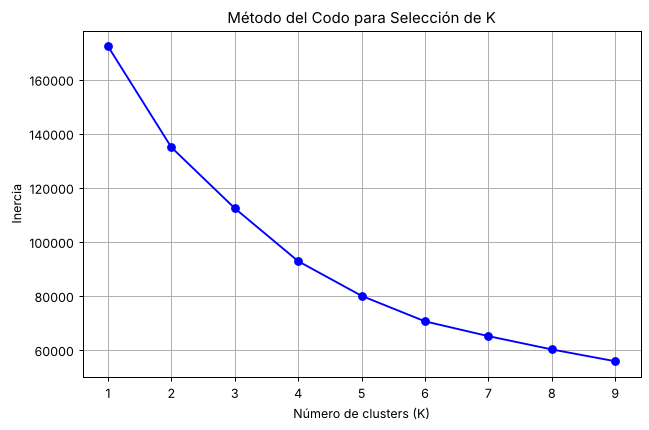

In [51]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

# Método del Codo para encontrar la cantidad óptima de clusters (K)
inertias = []
K_range = range(1, 10)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inertias.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(K_range, inertias, marker='o', linestyle='-', color='b')
plt.title('Método del Codo para Selección de K')
plt.xlabel('Número de clusters (K)')
plt.ylabel('Inercia')
plt.grid(True)
plt.show()

      inercia  silhouette  davies_bouldin  calinski_harabasz
K                                                           
2  134944.226       0.276           1.528           7955.719
3  112399.156       0.241           1.423           7655.744
4   92833.884       0.244           1.161           8196.681
5   80025.088       0.257           1.080           8280.273
6   70584.296       0.229           1.108           8278.090
7   65124.776       0.219           1.173           7877.679
8   60205.069       0.219           1.106           7639.012

K con mayor silhouette         : 2
K con menor Davies-Bouldin     : 5
K con mayor Calinski-Harabasz  : 5


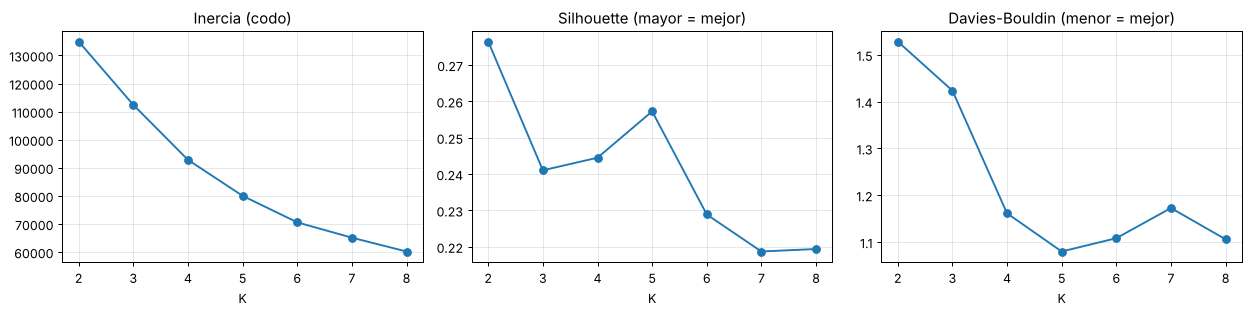

In [52]:
# --- Métricas de calidad del clustering (K = 2 a 8) ---
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
rng = np.random.RandomState(42)
sub = rng.choice(len(X_scaled), 8000, replace=False)      # silhouette es O(n²): se calcula sobre una muestra
filas = []
for k in range(2, 9):
    km_ = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X_scaled)
    filas.append((k, km_.inertia_, silhouette_score(X_scaled[sub], km_.labels_[sub]),
                  davies_bouldin_score(X_scaled, km_.labels_), calinski_harabasz_score(X_scaled, km_.labels_)))
metricas = pd.DataFrame(filas, columns=['K','inercia','silhouette','davies_bouldin','calinski_harabasz']).set_index('K')
print(metricas.round(3))
print()
print('K con mayor silhouette         :', metricas.silhouette.idxmax())
print('K con menor Davies-Bouldin     :', metricas.davies_bouldin.idxmin())
print('K con mayor Calinski-Harabasz  :', metricas.calinski_harabasz.idxmax())
fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
for a, col, t_ in zip(ax, ['inercia','silhouette','davies_bouldin'], ['Inercia (codo)','Silhouette (mayor = mejor)','Davies-Bouldin (menor = mejor)']):
    a.plot(metricas.index, metricas[col], 'o-'); a.set_title(t_); a.set_xlabel('K'); a.grid(alpha=.3)
plt.tight_layout(); plt.show()

### 3. Aplicación del Algoritmo K-Means y Justificación del Criterio
* **Criterio de decisión:** el codo no marca un punto de inflexión nítido, por lo que se apoya la elección en métricas. El *silhouette* más alto corresponde a $K = 2$ (0,276), pero ese corte separa sobre todo registros cálidos de fríos (efecto estacional). $K = 5$ tiene el menor Davies-Bouldin (1,080) y el mayor Calinski-Harabasz (8.280) y su *silhouette* (0,257) es el segundo mejor. Se selecciona **$K = 5$**.
* **Limitación:** un *silhouette* menor a 0,3 indica estructura débil: los grupos se solapan y deben interpretarse como tipologías aproximadas, no como regímenes bien separados.

In [53]:
k_optimo = 5
kmeans = KMeans(n_clusters=k_optimo, random_state=42, n_init=10)
clusters = kmeans.fit_predict(X_scaled)

# Guardar los clusters en el DataFrame original
X_cluster['cluster'] = clusters

In [54]:
# Calcular el promedio de las variables originales por cada cluster, con su tamaño
perfil_clusters = X_cluster.groupby('cluster').mean()
perfil_clusters['n'] = X_cluster.groupby('cluster').size()
perfil_clusters['% del total'] = (perfil_clusters['n'] / len(X_cluster) * 100).round(2)
print(perfil_clusters.round(2).to_string())

# Calidad del K elegido
print('\nK elegido =', k_optimo)
print('Silhouette (muestra de 8000):', round(silhouette_score(X_scaled[sub], clusters[sub]), 3))
print('Davies-Bouldin             :', round(davies_bouldin_score(X_scaled, clusters), 3))
print('Calinski-Harabasz          :', round(calinski_harabasz_score(X_scaled, clusters), 1))

         temp_c  hr_porc  press_mbar  pluv_mm  rad_sol_w_m2  vv_m_s      n  % del total
cluster                                                                                
0         20.46    90.73     1006.33    96.17          2.19    1.14     52         0.18
1         26.96    50.60     1010.28     0.02        629.06    0.86   4506        15.69
2         19.19    66.13     1011.65     0.33        121.08    2.68   2622         9.13
3         14.03    69.12     1016.32     0.09         41.53    0.38   9144        31.84
4         23.33    69.67     1008.48     0.39         41.85    0.35  12397        43.16

K elegido = 5
Silhouette (muestra de 8000): 0.257
Davies-Bouldin             : 1.08
Calinski-Harabasz          : 8280.3


### 4. Interpretación y Caracterización de los Clusters Encontrados
Perfil de los centroides ($K = 5$; silhouette 0,257, Davies-Bouldin 1,080, Calinski-Harabasz 8.280):

* **Cluster 4 (Templado, radiación baja) – 43,2 %:** 23,3 °C, 41,9 W/m², viento débil. Horas de tarde-noche o mañanas templadas.
* **Cluster 3 (Fresco / madrugadas) – 31,8 %:** 14,0 °C y la mayor presión (1016,3 mbar), con radiación baja. Mezcla horas nocturnas y los meses más fríos.
* **Cluster 1 (Cálido y soleado) – 15,7 %:** 27,0 °C, 629 W/m² y humedad baja (50,6 %): horas diurnas de mayor insolación.
* **Cluster 2 (Ventoso) – 9,1 %:** 19,2 °C con viento de 2,68 m/s, claramente superior al resto.
* **Cluster 0 (Lluvia extrema) – 0,18 % (52 registros):** lluvia promedio de 96,2 mm, humedad de 90,7 % y radiación casi nula. Es un grupo muy pequeño y sus valores de `pluv_mm` (hasta 237 mm en un registro) deberían verificarse (lluvia real, acumulado o falla del sensor) antes de interpretarlo como «tormentas».

Las variables de clustering no incluyen la hora ni el mes, por lo que los grupos mezclan ciclo diario y estacionalidad. Con un *silhouette* bajo, la segmentación es útil como descripción, pero no demuestra regímenes climáticos bien definidos.